# Proteome and transcriptome dataset generation

Produces the processed tables used by every analysis. Proteins and transcripts go through the same pipeline, on the same tumors and the same genes.

**Pipeline (per cohort and omic)**
1. Read the table, exclude samples that are not part of the study, average technical replicates (proteome).
2. Keep tumors present in both omics.
3. Gene filters: transcripts with a TPM of 0 in any tumor are removed, duplicated gene symbols are averaged, genes with any missing value are removed.
4. Keep genes that pass both omics' filters.
5. Normalize: divide each gene by its mean across tumors, divide each tumor by its median across genes, take log2, then divide each tumor by its robust spread, (Q75 - Q25) / 1.349, across its genes.
6. Export the tables at each cohort's own number of tumors (native length), plus a 77-value nearest-rank version for models that need a fixed length.

## Set up

In [5]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### Settings

In [11]:
raw_data_path = 'raw_datasets/'
output_path = 'processed_datasets_prot_mrna/'
Path(output_path).mkdir(parents=True, exist_ok=True)

# Keep a gene if it is quantified in at least this fraction of tumors (1.0 = complete cases).
MIN_FRACTION_OBSERVED = 1.0

# Restrict both omics to shared tumors (before gene filters) and shared genes (before normalization).
SHARED_TUMORS_ONLY = True
SHARED_GENES_ONLY = True

# Length of the fixed nearest-rank vector exported for models that need a fixed input length.
# 77 is the size of the smallest cohort (Mertins).
FIXED_LENGTH = 77

# IQR / 1.349 equals the SD for normally distributed data.
IQR_TO_SD = 1.349

### Log

In [7]:
# Genes and samples after each step, per cohort and omic. Written to preprocessing_flow.csv.
flow = []
def log_step(cohort, omic, step, df):
    flow.append({'cohort': cohort, 'omic': omic, 'step': step, 'n_genes': df.shape[0], 'n_samples': df.shape[1]})

### Functions

In [8]:
def drop_columns_by_keyword(df, keywords):
    """Remove every column whose name contains any of the keywords (plain-text match)."""
    for kw in keywords:
        df = df.loc[:, ~df.columns.str.contains(kw, regex=False)]
    return df


def average_replicates(df):
    """
    Average technical replicates. A column named '<tumor>.REP...' is a replicate of column '<tumor>';
    all columns that share the same <tumor> are averaged. NaN is skipped.
    """
    base = df.columns.str.replace(r'\.REP.*$', '', regex=True)
    if (base == df.columns).all():
        return df
    return df.T.groupby(np.asarray(base)).mean().T


def Normalization(df):
    """
    df: genes x tumors, positive abundances (protein ratios to the pooled reference, or TPM).
      1. divide each gene by its mean across tumors
      2. divide each tumor by its median across genes
      3. log2
      4. divide each tumor by its robust spread (Q75 - Q25) / 1.349 across its genes
    """
    assert np.nanmin(df.to_numpy()) > 0, 'Abundances must be positive before log2'
    df = df.div(df.mean(axis=1), axis=0)
    df = df.div(df.median(axis=0), axis=1)
    df = np.log2(df)
    q75, q25 = df.quantile(0.75, axis=0), df.quantile(0.25, axis=0)
    spread = (q75 - q25) / IQR_TO_SD
    assert (spread > 0).all(), 'A tumor has zero spread'
    return df.div(spread, axis=1)


def nearest_rank_vectors(df, length=FIXED_LENGTH):
    """
    For fixed-length input. Each gene's tumor values are sorted and the
    value at the nearest rank of `length` evenly spaced relative ranks is taken, so every
    entry is a real measurement. A cohort with fewer tumors than `length` repeats values.
    """
    n = df.shape[1]
    idx = np.rint(np.linspace(0, n - 1, length)).astype(int)
    vals = np.sort(df.to_numpy(), axis=1)[:, idx]
    return pd.DataFrame(vals, index=df.index, columns=[f'rank{i + 1}' for i in range(length)])


def VisualizeData(df, title=''):
    """Per-tumor boxplots and the overall histogram of a processed table."""
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.boxplot([df[c].dropna().values for c in df.columns], showfliers=False)
    plt.title(title); plt.xlabel('Tumors'); plt.ylabel('Abundances'); plt.xticks([])
    plt.subplot(1, 2, 2)
    v = df.values.flatten(); plt.hist(v[~np.isnan(v)], bins=500)
    plt.title(title); plt.xlabel('Abundance'); plt.ylabel('Count')
    plt.tight_layout(); plt.show()

### Pipeline

In [9]:
def load_proteome(name, cfg):
    """Read the protein table (ratios to the pool, untransformed) and clean the samples."""
    df = pd.read_csv(raw_data_path + cfg['file'], index_col=cfg['index_col'])
    log_step(name, 'proteome', 'raw table', df)
    df = drop_columns_by_keyword(df, cfg['drop_keywords'])
    if cfg.get('strip_suffix'):
        df.columns = df.columns.str.replace(cfg['strip_suffix'], '', regex=False)
    log_step(name, 'proteome', 'after sample exclusions', df)
    df = average_replicates(df)
    log_step(name, 'proteome', 'after averaging replicates', df)
    return df


def load_transcriptome(name, cfg):
    df = pd.read_csv(raw_data_path + cfg['mrna_file'], index_col=cfg['mrna_index_col'])
    log_step(name, 'transcriptome', 'raw table', df)
    return df


def filter_genes(name, omic, df):
    if omic == 'transcriptome':
        df = df.loc[~(df == 0).any(axis=1)]          # log2 needs TPM > 0
        log_step(name, omic, 'after removing zero-TPM genes', df)
    df = df.groupby(level=0).mean()                   # merge duplicated gene symbols
    log_step(name, omic, 'after merging duplicate gene symbols', df)
    df = df.loc[df.notna().mean(axis=1) >= MIN_FRACTION_OBSERVED]
    log_step(name, omic, f'after missing-value filter (>= {MIN_FRACTION_OBSERVED:.0%} observed)', df)
    return df


def process_cohort(name, cfg):
    """Raw tables -> normalized proteome and transcriptome (genes x real tumors)."""
    prot, mrna = load_proteome(name, cfg), load_transcriptome(name, cfg)

    if SHARED_TUMORS_ONLY:
        shared = [c for c in prot.columns if c in mrna.columns]
        if len(shared) < prot.shape[1]:
            print(f'{name}: {prot.shape[1] - len(shared)} proteome tumors have no mRNA data and are dropped')
        prot, mrna = prot.loc[:, shared], mrna.loc[:, shared]
        log_step(name, 'proteome', 'after matching tumors', prot)
        log_step(name, 'transcriptome', 'after matching tumors', mrna)

    prot = filter_genes(name, 'proteome', prot)
    mrna = filter_genes(name, 'transcriptome', mrna)

    if SHARED_GENES_ONLY:
        genes = prot.index.intersection(mrna.index)
        prot, mrna = prot.loc[genes], mrna.loc[genes]
        log_step(name, 'proteome', 'after matching genes', prot)
        log_step(name, 'transcriptome', 'after matching genes', mrna)

    prot = prot.reindex(sorted(prot.columns), axis=1)
    mrna = mrna.reindex(sorted(mrna.columns), axis=1)

    prot, mrna = Normalization(prot), Normalization(mrna)
    log_step(name, 'proteome', 'processed (mean, tumor median, log2, robust scaling)', prot)
    log_step(name, 'transcriptome', 'processed (mean, tumor median, log2, robust scaling)', mrna)
    return prot, mrna

### Cohort set up

In [4]:
# index_col / mrna_index_col: column holding the gene symbol in the raw csv
# drop_keywords: proteome samples whose column name contains any of these are excluded
COHORTS = {
    'Training': dict(file='krug prot model use.csv', index_col='Index',
                 mrna_file='krug mrna model use.csv', mrna_index_col='Index',
                 drop_keywords=['notinstudy', 'Retro'], out='Training'),
    'Breast_tumor': dict(file='breast prot model use.csv', index_col='Index',
                    mrna_file='breast mrna model use.csv', mrna_index_col='gene_name',
                    drop_keywords=['notinstudy'], out='breast_tumor'),
    'Lung_tumor': dict(file='lung tumor prot model use.csv', index_col=0,
                        mrna_file='lung tumor mrna model use.csv', mrna_index_col=0,
                        drop_keywords=[], out='lung_tumor'),
    'Lung_NAT': dict(file='lung nat prot model use.csv', index_col=0,
                      mrna_file='lung nat mrna model use.csv', mrna_index_col=0,
                      drop_keywords=[], out='lung_nat'),
    'Brain_tumor': dict(file='brain prot model use.csv', index_col=0,
                   mrna_file='brain mrna model use.csv', mrna_index_col=0,
                   drop_keywords=['Disqualified', 'Recurrent', 'Metastatic', 'Solid-Tissue-Normal', 'ref2'],
                   strip_suffix='-Primary-Tumor', out='brain_tumor'),
}
processed_prot, processed_mrna = {}, {}

## Create dataframes

In [13]:
for name, cfg in COHORTS.items():
    processed_prot[name], processed_mrna[name] = process_cohort(name, cfg)
    print(name, 'proteome', processed_prot[name].shape, '| transcriptome', processed_mrna[name].shape)

Training: 1 proteome tumors have no mRNA data and are dropped
Training proteome (7902, 121) | transcriptome (7902, 121)
Breast_tumor proteome (6733, 77) | transcriptome (6733, 77)
Lung_tumor proteome (8608, 108) | transcriptome (8608, 108)
Lung_NAT proteome (8658, 94) | transcriptome (8658, 94)
Brain_tumor: 3 proteome tumors have no mRNA data and are dropped
Brain_tumor proteome (8189, 99) | transcriptome (8189, 99)


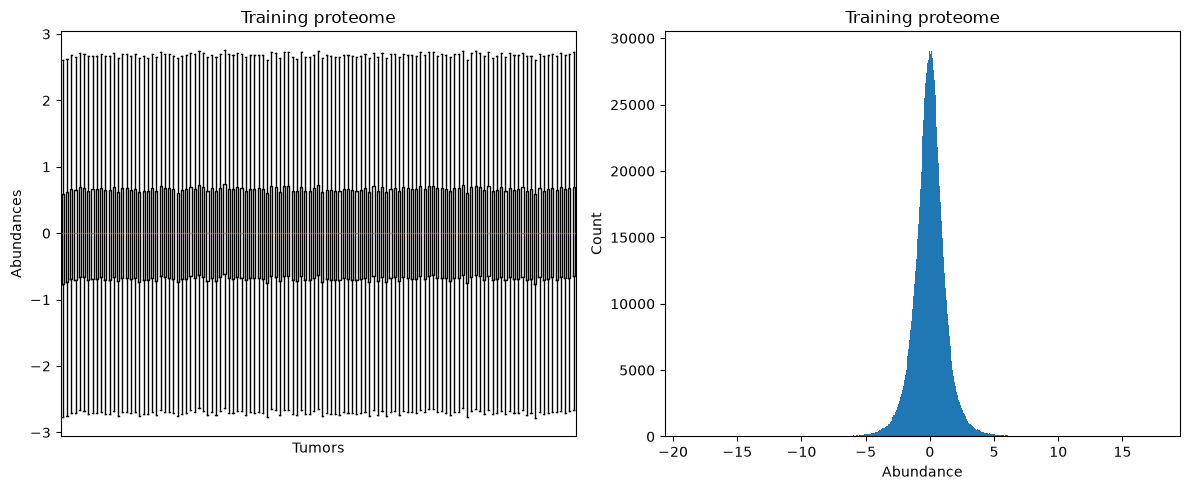

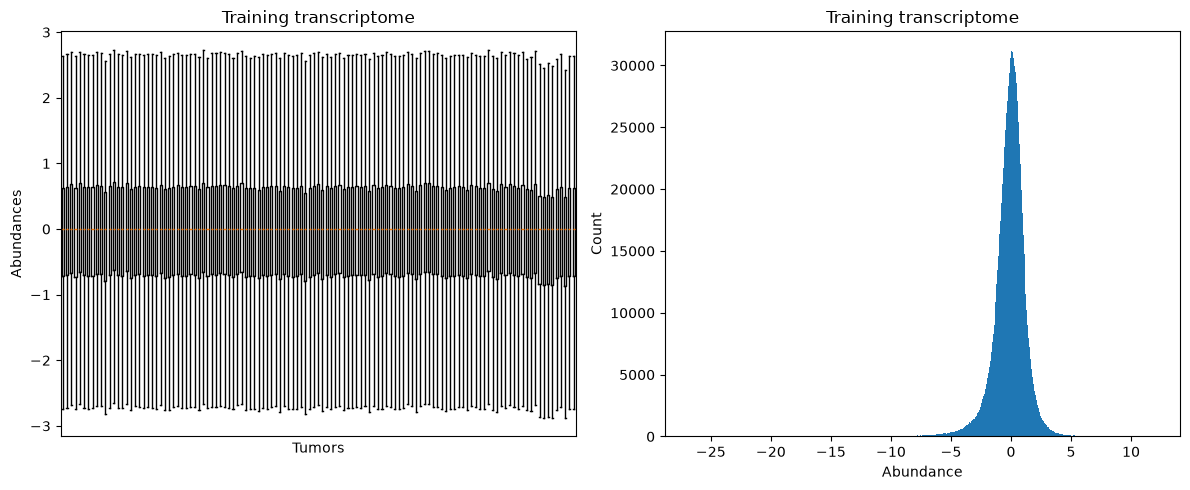

In [14]:
VisualizeData(processed_prot['Training'], 'Training proteome')
VisualizeData(processed_mrna['Training'], 'Training transcriptome')

### Checkpoint

In [15]:
overlap = pd.DataFrame([
    dict(cohort=n,
         n_proteins=processed_prot[n].shape[0], n_transcripts=processed_mrna[n].shape[0],
         n_shared_genes=len(processed_prot[n].index.intersection(processed_mrna[n].index)),
         n_proteome_tumors=processed_prot[n].shape[1], n_transcriptome_tumors=processed_mrna[n].shape[1],
         n_shared_tumors=len(processed_prot[n].columns.intersection(processed_mrna[n].columns)))
    for n in COHORTS])
if SHARED_GENES_ONLY:
    assert (overlap.n_proteins == overlap.n_shared_genes).all() and (overlap.n_transcripts == overlap.n_shared_genes).all()
if SHARED_TUMORS_ONLY:
    assert (overlap.n_proteome_tumors == overlap.n_shared_tumors).all() and (overlap.n_transcriptome_tumors == overlap.n_shared_tumors).all()

# Every tumor has robust spread 1 and median 0 is NOT imposed; check the spread and that no NaN remains.
for n in COHORTS:
    for df in (processed_prot[n], processed_mrna[n]):
        iqr = (df.quantile(0.75) - df.quantile(0.25)) / IQR_TO_SD
        assert np.allclose(iqr, 1.0) and not df.isna().any().any()
overlap

,cohort,n_proteins,n_transcripts,n_shared_genes,n_proteome_tumors,n_transcriptome_tumors,n_shared_tumors
0,Training,7902,7902,7902,121,121,121
1,Breast_tumor,6733,6733,6733,77,77,77
2,Lung_tumor,8608,8608,8608,108,108,108
3,Lung_NAT,8658,8658,8658,94,94,94
4,Brain_tumor,8189,8189,8189,99,99,99


## Model inputs

* **Native length (main input):** `*_PD_processed.csv` and `*_MD_processed.csv`, genes x real tumors. The training notebooks sort each gene's values (rank order, no tumor identity) and standardize each rank position with the Krug training proteins, interpolated by relative rank for cohorts of another size. Per-protein statistics and co-regulation analyses also use these tables.
* **Fixed length:** `*_PD_NR{FIXED_LENGTH}.csv` and `*_MD_NR{FIXED_LENGTH}.csv`, genes x {FIXED_LENGTH} nearest-rank values of the sorted vector, for logistic regression, kNN and the MLP.

Gene filtering by localization labels is done in the training notebooks, with splits built over proteins so that the same protein is never in training and test.

In [ ]:
# Fixed length is set to 77 values for the nearest-rank vectors, which is the size of the smallest cohort (Mertins' breast tumor cohort).
nr_prot = {n: nearest_rank_vectors(df) for n, df in processed_prot.items()}
nr_mrna = {n: nearest_rank_vectors(df) for n, df in processed_mrna.items()}
{n: (nr_prot[n].shape, nr_mrna[n].shape) for n in COHORTS}

{'Training': ((7902, 77), (7902, 77)),
 'Breast_tumor': ((6733, 77), (6733, 77)),
 'Lung_tumor': ((8608, 77), (8608, 77)),
 'Lung_NAT': ((8658, 77), (8658, 77)),
 'Brain_tumor': ((8189, 77), (8189, 77))}

## Export

In [17]:
for name in COHORTS:
    out = COHORTS[name]['out']
    processed_prot[name].to_csv(Path(output_path + f'{out}_PD_processed.csv'))
    processed_mrna[name].to_csv(Path(output_path + f'{out}_MD_processed.csv'))
    nr_prot[name].to_csv(Path(output_path + f'{out}_PD_NR{FIXED_LENGTH}.csv'))
    nr_mrna[name].to_csv(Path(output_path + f'{out}_MD_NR{FIXED_LENGTH}.csv'))

flow_df = pd.DataFrame(flow)
flow_df.to_csv(Path(output_path + 'preprocessing_flow.csv'), index=False)
overlap.to_csv(Path(output_path + 'gene_sample_overlap.csv'), index=False)

settings = dict(normalization='gene mean division; tumor median division; log2; tumor robust scaling (IQR/1.349)',
                MIN_FRACTION_OBSERVED=MIN_FRACTION_OBSERVED, SHARED_TUMORS_ONLY=SHARED_TUMORS_ONLY,
                SHARED_GENES_ONLY=SHARED_GENES_ONLY, FIXED_LENGTH=FIXED_LENGTH,
                versions=dict(numpy=np.__version__, pandas=pd.__version__), cohorts=COHORTS)
with open(Path(output_path + 'preprocessing_settings.json'), 'w') as f:
    json.dump(settings, f, indent=2)

flow_df

,cohort,omic,step,n_genes,n_samples
0,Training,proteome,raw table,12667,135
1,Training,proteome,after sample exclusions,12667,130
2,Training,proteome,after averaging replicates,12667,122
3,Training,transcriptome,raw table,19938,121
4,Training,proteome,after matching tumors,12667,121
...,...,...,...,...,...
70,Brain_tumor,transcriptome,after missing-value filter (>= 100% observed),15194,99
71,Brain_tumor,proteome,after matching genes,8189,99
72,Brain_tumor,transcriptome,after matching genes,8189,99
73,Brain_tumor,proteome,"processed (mean, tumor median, log2, robust sc...",8189,99
